# Errores comunes al diseñar gráficos

El caso conductor de la unidad es una encuesta de satisfacción de clientes de una cadena de supermercados, con datos de producto, trimestre, satisfacción, ventas y número de clientes. A partir de esta tabla se plantean preguntas analíticas que guían la elección del gráfico y la aplicación de los principios de percepción, claridad y honestidad visual.


## Eje truncado y escalas engañosas

Cuando se representa una cantidad mediante barras, la longitud de cada barra debería ser proporcional al valor que representa. Si el eje no comienza en cero sino en un valor arbitrario, las longitudes dejan de reflejar las magnitudes reales y la comparación visual resulta distorsionada. Este problema se agrava si se usa una escala logarítmica: en ella el valor cero no puede representarse y el origen de las barras se elige de forma arbitraria, por lo que las longitudes pueden manipularse desplazando ese origen. En consecuencia, las barras en escala logarítmica tampoco permiten una lectura fiel de los datos.

**Ejemplo:** En la encuesta de satisfacción de clientes, si se grafican las ventas por producto con barras que comienzan en un valor distinto de cero, las longitudes no reflejan las diferencias reales entre productos y la comparación induce a error.

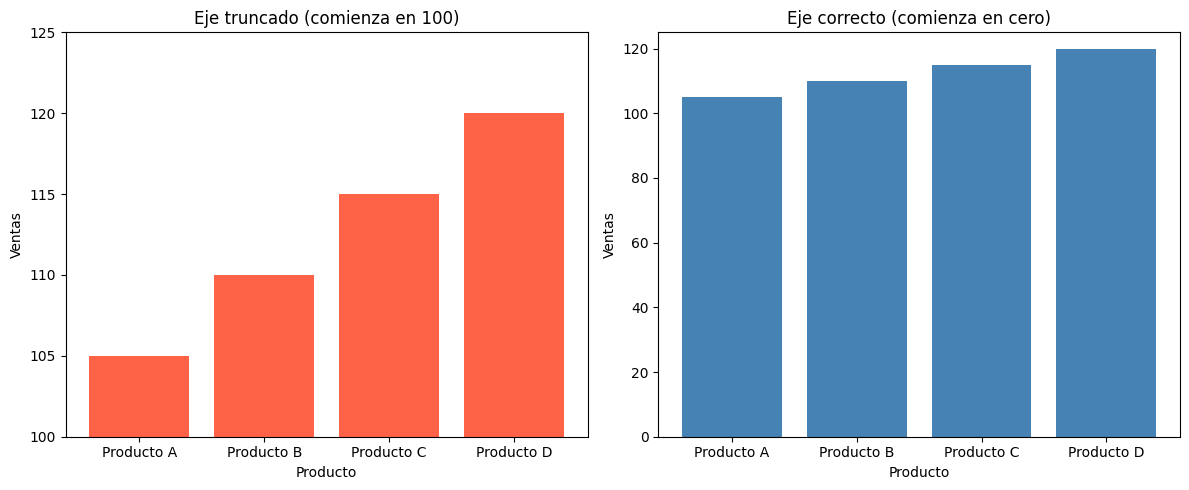

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Datos de la encuesta de satisfacción: ventas por producto
datos = pd.DataFrame({
    'producto': ['Producto A', 'Producto B', 'Producto C', 'Producto D'],
    'ventas': [105, 110, 115, 120]
})

# Creamos dos gráficos para comparar el efecto del eje truncado
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico 1: eje truncado (comienza en 100 en lugar de cero)
ax1.bar(datos['producto'], datos['ventas'], color='tomato')
ax1.set_ylim(100, 125)
ax1.set_title('Eje truncado (comienza en 100)')
ax1.set_xlabel('Producto')
ax1.set_ylabel('Ventas')

# Gráfico 2: eje correcto que comienza en cero
ax2.bar(datos['producto'], datos['ventas'], color='steelblue')
ax2.set_ylim(0, 125)
ax2.set_title('Eje correcto (comienza en cero)')
ax2.set_xlabel('Producto')
ax2.set_ylabel('Ventas')

# Ajustamos el espacio entre los gráficos
plt.tight_layout()
plt.show()

**Errores frecuentes:**
- Comenzar las barras en un valor arbitrario distinto de cero, de modo que las longitudes no reflejen los valores reales.
- Usar una escala logarítmica en barras para representar cantidades, lo que obliga a fijar un origen arbitrario y distorsiona las longitudes.

## Gráfico circular con demasiadas categorías

Un gráfico circular representa proporciones mediante porciones de un círculo. Cuando se intenta mostrar demasiadas categorías, el espacio disponible se reduce y cada porción se vuelve difícil de distinguir y comparar. Por eso conviene limitar el número de porciones a ocho; si hay más de ocho proporciones para representar, es preferible considerar un gráfico de barras. La razón es que el espacio real es limitado y resulta complicado representar e interpretar las piezas de manera significativa. Esta recomendación también se aplica cuando los gráficos circulares se superponen sobre mapas para resaltar tendencias geográficas: las porciones deben limitarse igualmente.

**Ejemplo:** Al analizar la distribución de clientes por producto en la encuesta de satisfacción, se identifican más de ocho categorías de producto. Si se intenta representar todas en un gráfico circular, las porciones resultantes son muy pequeñas y difíciles de comparar. En ese caso, corresponde optar por un gráfico de barras para mostrar las proporciones de clientes por producto.

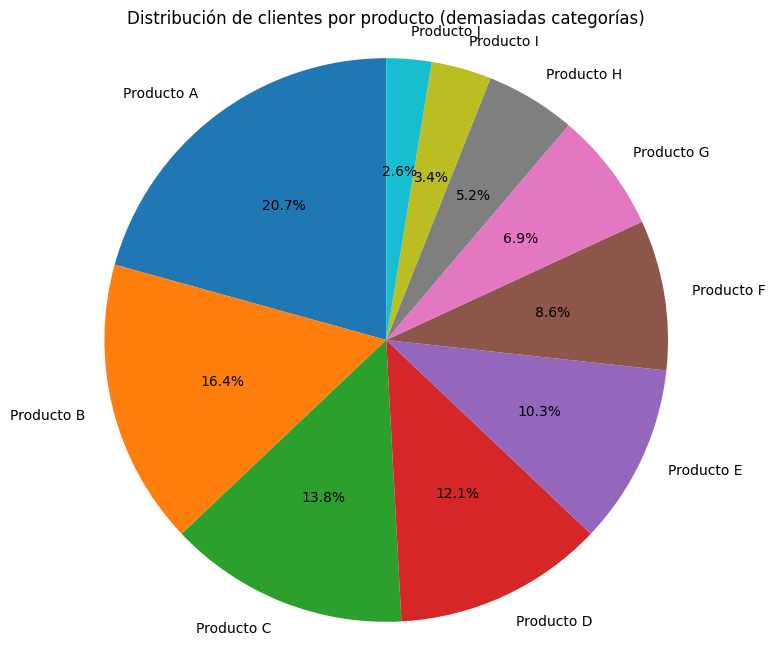

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Datos de la encuesta: cantidad de clientes por producto (más de ocho categorías)
datos = {
    'Producto': ['Producto A', 'Producto B', 'Producto C', 'Producto D', 'Producto E',
                 'Producto F', 'Producto G', 'Producto H', 'Producto I', 'Producto J'],
    'Clientes': [120, 95, 80, 70, 60, 50, 40, 30, 20, 15]
}
df = pd.DataFrame(datos)

# Gráfico circular con demasiadas categorías: las porciones se vuelven muy pequeñas
fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(df['Clientes'], labels=df['Producto'], autopct='%1.1f%%', startangle=90)
ax.set_title('Distribución de clientes por producto (demasiadas categorías)')
ax.axis('equal')
plt.show()

# Alternativa recomendada: gráfico de barras para comparar las proporciones
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(df['Producto'], df['Clientes'], color='steelblue')
ax.set_title('Clientes por producto (gráfico de barras recomendado)')
ax.set_xlabel('Producto')
ax.set_ylabel('Cantidad de clientes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Errores frecuentes:**
- Incluir más de ocho porciones en un gráfico circular, lo que dificulta la representación e interpretación de las piezas.
- No considerar un gráfico de barras cuando hay más de ocho proporciones para representar.

## Efectos tridimensionales y decoración excesiva

Cuando un gráfico circular se representa en tres dimensiones, la perspectiva hace que las porciones ubicadas en la parte delantera parezcan más grandes de lo que realmente son, mientras que las porciones ubicadas en la parte trasera parecen más pequeñas. Este efecto óptico distorsiona la proporción que cada categoría ocupa en el total, de modo que una porción que representa un porcentaje determinado puede visualmente ocupar un área mayor o menor que la que le corresponde. El problema no se limita a los gráficos circulares: en otros tipos de gráficos tridimensionales, como las barras en 3D, la disposición relativa a los ejes y la distancia a las superficies de fondo generan ilusiones similares, haciendo que las columnas parezcan más cortas de lo que son. En ambos casos, la decoración tridimensional introduce una lectura inexacta de los datos, por lo que solo una representación plana y bien alineada con los ejes permite una interpretación fiel de las magnitudes.

**Ejemplo:** Al comparar la satisfacción promedio por producto en un gráfico circular 3D, la porción del producto con mayor satisfacción, situada al frente, aparenta abarcar una proporción mayor que la que le corresponde según los datos, mientras que la porción de otro producto, ubicada al fondo, se ve más pequeña de lo real. Si se usaran barras 3D para mostrar las ventas por trimestre, las columnas parecerían más bajas de lo que indican los valores, porque están separadas de las líneas de fondo que marcan la escala.

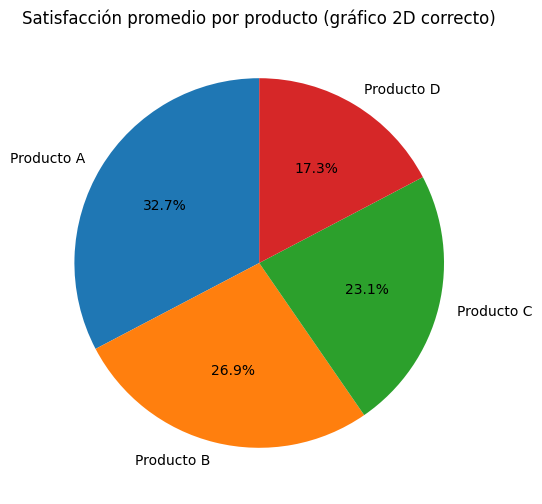

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Datos de satisfacción promedio por producto
productos = ['Producto A', 'Producto B', 'Producto C', 'Producto D']
satisfaccion = [85, 70, 60, 45]

# --- Gráfico circular 2D correcto ---
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(satisfaccion, labels=productos, autopct='%1.1f%%', startangle=90)
ax.set_title('Satisfacción promedio por producto (gráfico 2D correcto)')
plt.show()

# --- Simulación del efecto 3D: distorsión de proporciones ---
# En un gráfico circular 3D, las porciones al frente se ven más grandes
# y las del fondo más pequeñas. Simulamos esa distorsión con barras.
factor_distorsion = [1.25, 1.10, 0.90, 0.75]  # frente grande, fondo chico
satisfaccion_aparente = [s * f for s, f in zip(satisfaccion, factor_distorsion)]

x = np.arange(len(productos))
ancho = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - ancho/2, satisfaccion, ancho, label='Valor real', color='steelblue')
ax.bar(x + ancho/2, satisfaccion_aparente, ancho, label='Valor aparente (efecto 3D)', color='salmon')
ax.set_xticks(x)
ax.set_xticklabels(productos)
ax.set_ylabel('Satisfacción promedio')
ax.set_title('Distorsión visual por efecto tridimensional')
ax.legend()
plt.show()

# --- Simulación de barras 3D: columnas que parecen más bajas ---
trimestres = ['T1', 'T2', 'T3', 'T4']
ventas = [120, 150, 130, 170]
ventas_aparentes = [v * 0.8 for v in ventas]  # se ven más bajas de lo real

x = np.arange(len(trimestres))
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - ancho/2, ventas, ancho, label='Valor real', color='seagreen')
ax.bar(x + ancho/2, ventas_aparentes, ancho, label='Valor aparente (barras 3D)', color='goldenrod')
ax.set_xticks(x)
ax.set_xticklabels(trimestres)
ax.set_ylabel('Ventas')
ax.set_title('Barras 3D: columnas que parecen más bajas')
ax.legend()
plt.show()

**Errores frecuentes:**
- Usar gráficos circulares en 3D que hacen que las porciones delanteras parezcan más grandes y las traseras más pequeñas de lo que son.
- Emplear barras en 3D que, por su disposición respecto de los ejes y las superficies de fondo, hacen que las columnas parezcan más cortas de lo que realmente son.

## Tipo de gráfico inadecuado al mensaje

Cada tipo de gráfico tiene ventajas y limitaciones para comunicar un mensaje. El gráfico de dispersión conectado puede resultar atractivo, pero la investigación muestra que los lectores confunden con mayor frecuencia el orden y la dirección de los puntos que en los gráficos de líneas, y además son menos propensos a informar una correlación. Esto implica que, si el objetivo es que el público comprenda la relación entre dos variables, conviene evaluar si este tipo de gráfico es el adecuado o si un gráfico de líneas separadas facilita mejor la lectura. La elección del gráfico debe alinearse con el mensaje que se quiere transmitir y con la capacidad del lector para interpretarlo correctamente.

**Ejemplo:** Para mostrar la evolución conjunta de la satisfacción promedio y las ventas trimestrales, un gráfico de dispersión conectado podría llevar a confundir el orden de los trimestres y la dirección de los cambios; en cambio, dos gráficos de líneas separados permitirían comparar las tendencias con mayor claridad.

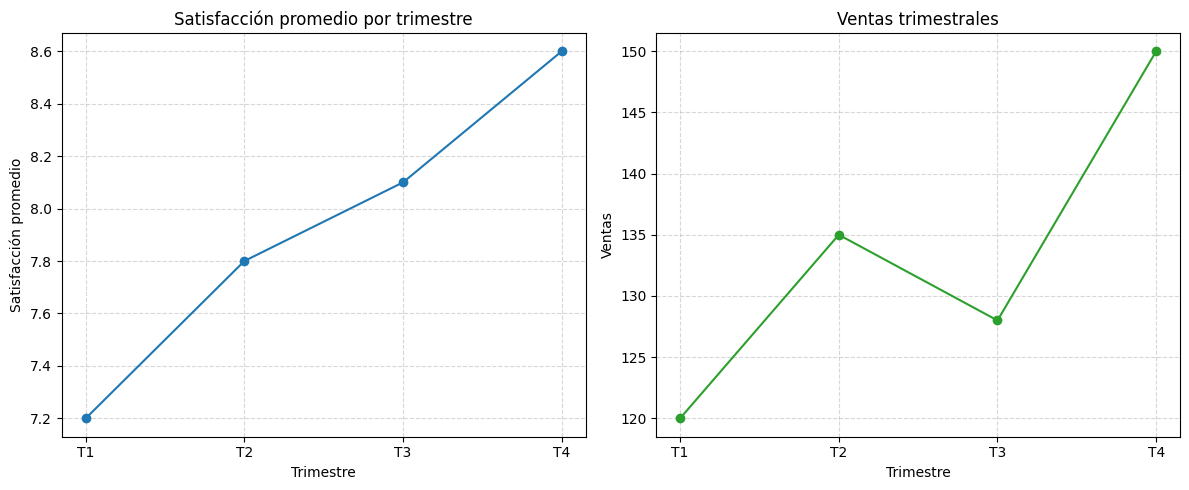

In [ ]:
import matplotlib.pyplot as plt

# Datos ilustrativos: satisfacción promedio y ventas por trimestre
trimestres = ['T1', 'T2', 'T3', 'T4']
satisfaccion = [7.2, 7.8, 8.1, 8.6]
ventas = [120, 135, 128, 150]

# Creamos dos gráficos de líneas separados para comparar tendencias con claridad
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Primer gráfico: evolución de la satisfacción promedio
ax1.plot(trimestres, satisfaccion, marker='o', color='tab:blue')
ax1.set_title('Satisfacción promedio por trimestre')
ax1.set_xlabel('Trimestre')
ax1.set_ylabel('Satisfacción promedio')
ax1.grid(True, linestyle='--', alpha=0.5)

# Segundo gráfico: evolución de las ventas trimestrales
ax2.plot(trimestres, ventas, marker='o', color='tab:green')
ax2.set_title('Ventas trimestrales')
ax2.set_xlabel('Trimestre')
ax2.set_ylabel('Ventas')
ax2.grid(True, linestyle='--', alpha=0.5)

# Ajustamos el espacio entre los gráficos
plt.tight_layout()
plt.show()

**Errores frecuentes:**
- Confundir el orden y la dirección de los puntos en un gráfico de dispersión conectado.
- No informar correctamente la correlación entre las variables.

## Saturación visual y sobrecarga de elementos

La saturación visual ocurre cuando un gráfico acumula elementos que no aportan información: ejes, etiquetas, puntos de datos, líneas de cuadrícula, animaciones o gifs. Cada uno de estos componentes debe evaluarse críticamente: si eliminarlo no cambia el mensaje que se quiere transmitir, conviene suprimirlo. El cerebro se distrae con rapidez ante contenido animado o recargado, por lo que las animaciones solo se justifican cuando cumplen una función muy clara. Herramientas de visualización suelen ofrecer opciones para reducir el desorden, y aunque sus valores por defecto sean razonables, siempre es posible ajustarlas para lograr una presentación más limpia y enfocada en los datos relevantes.

**Ejemplo:** Al construir un gráfico de líneas para mostrar la evolución trimestral de la satisfacción, se opta por quitar la cuadrícula de fondo, reducir las etiquetas del eje vertical a solo tres valores de referencia y eliminar cualquier animación de entrada. Así, la atención se concentra en la tendencia de la satisfacción y no en elementos decorativos.

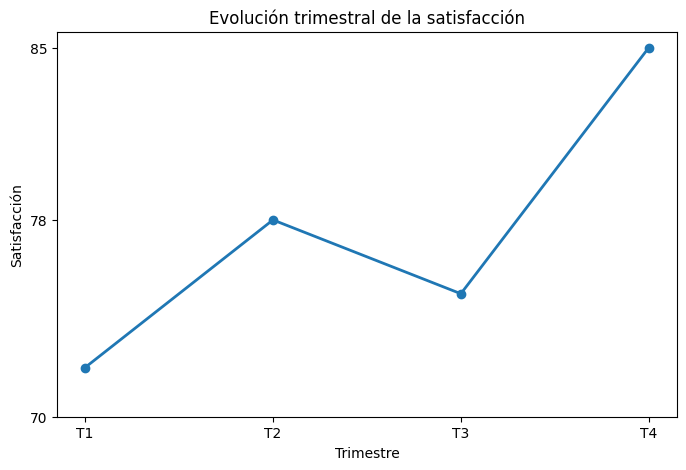

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Datos ilustrativos: satisfacción trimestral
trimestres = ['T1', 'T2', 'T3', 'T4']
satisfaccion = [72, 78, 75, 85]
df = pd.DataFrame({'trimestre': trimestres, 'satisfaccion': satisfaccion})

# Creamos la figura y el eje
fig, ax = plt.subplots(figsize=(8, 5))

# Graficamos la línea de la tendencia de satisfacción
ax.plot(df['trimestre'], df['satisfaccion'], marker='o', color='#1f77b4', linewidth=2)

# Quitamos la cuadrícula de fondo para reducir el ruido visual
ax.grid(False)

# Reducimos las etiquetas del eje vertical a solo tres valores de referencia
ax.set_yticks([70, 78, 85])

# Títulos y etiquetas claras y enfocadas en los datos
ax.set_title('Evolución trimestral de la satisfacción')
ax.set_xlabel('Trimestre')
ax.set_ylabel('Satisfacción')

# Mostramos el gráfico limpio, sin animaciones ni elementos decorativos
plt.show()

**Errores frecuentes:**
- Incluir animaciones o gifs sin una razón muy justificada que distraen la atención.
- Mantener elementos como ejes, etiquetas o líneas de cuadrícula que no aportan información y saturan el gráfico.

## Práctica

El siguiente código intenta mostrar la distribución de clientes por producto en la encuesta de satisfacción, pero tiene dos problemas conceptuales: usa un gráfico circular con más de ocho categorías (las porciones se vuelven ilegibles) y además aplica un efecto 3D que distorsiona las proporciones. Corregí el código reemplazando el gráfico circular 3D por un gráfico de barras plano (sin 3D) que muestre la cantidad de clientes por producto, manteniendo los mismos datos. Ejecutá el código y compará en tu cuaderno cómo cambia la lectura de las proporciones.


In [ ]:
import matplotlib.pyplot as plt

# Datos de la encuesta de satisfacción: clientes por producto
productos = ['Producto A', 'Producto B', 'Producto C', 'Producto D', 'Producto E', 'Producto F', 'Producto G', 'Producto H', 'Producto I', 'Producto J']
clientes = [120, 95, 80, 70, 60, 50, 40, 30, 20, 15]

# TODO: reemplazá este gráfico circular 3D por un gráfico de barras plano
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.pie(clientes, labels=productos, autopct='%1.1f%%')
plt.title('Distribución de clientes por producto')
plt.show()

### Solución


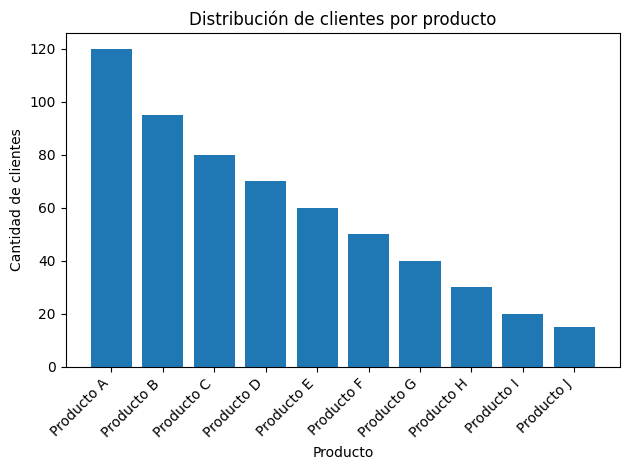

In [ ]:
import matplotlib.pyplot as plt

# Datos de la encuesta de satisfacción: clientes por producto
productos = ['Producto A', 'Producto B', 'Producto C', 'Producto D', 'Producto E', 'Producto F', 'Producto G', 'Producto H', 'Producto I', 'Producto J']
clientes = [120, 95, 80, 70, 60, 50, 40, 30, 20, 15]

# Gráfico de barras plano: más adecuado para muchas categorías y sin distorsión 3D
plt.bar(productos, clientes)
plt.title('Distribución de clientes por producto')
plt.xlabel('Producto')
plt.ylabel('Cantidad de clientes')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()